# Human Face Shape Classification with Machine Learning
### Reproduksi notebook dari paper *"Human Face Shape Classification with Machine Learning"* (Mehta & Mahmoud)

**Pipeline paper:**
1. Dataset: Kaggle *Face Shape Dataset* — 5.000 citra, 5 kelas (heart, oblong, oval, round, square).
2. Anotasi landmark: Dlib **81-point** facial landmark detector.
3. Hitung **7 jarak**, **10 rasio**, dan **3 sudut**.
4. Normalisasi jarak: $d'_i = d_i / \sum_{j=1}^{7} d_j$.
5. Seleksi fitur dengan **PCA** + feature importance dari classifier terbaik.
6. Klasifikasi dengan **Random Forest, Gradient Boosting, XGBoost**, 5-fold cross-validation.
7. Evaluasi: akurasi, classification report, confusion matrix.

**Catatan:** paper melaporkan akurasi **70%** pada subset 124 citra bersih. Notebook ini memakai dataset penuh (dibatasi `MAX_PER_CLASS` agar cepat) dan hasilnya bisa berbeda.

---
## 0. Instalasi dependensi
Jalankan sel di bawah jika paket belum tersedia. Di Windows, `dlib` biasanya butuh Visual Studio Build Tools; jika gagal, gunakan Python 3.10/3.11 atau conda.


In [16]:
# Di Windows + Python 3.13, JANGAN `pip install dlib` (butuh Visual C++).
# Gunakan wheel prebuilt:
# !pip install dlib-bin opencv-python scikit-learn pandas numpy matplotlib seaborn xgboost kagglehub tqdm joblib

# Alternatif jika memakai conda:
# conda install -c conda-forge dlib


## 1. Import dan konfigurasi

In [17]:
import os, sys, json, math, warnings, urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

# -----------------------------
# KONFIGURASI
# -----------------------------
CLASSES = ["heart", "oblong", "oval", "round", "square"]
RANDOM_STATE = 42
MAX_PER_CLASS = 120          # None = pakai semua gambar (lebih lambat)
TOP_K_FEATURES = 14          # paper memakai 14 fitur terpilih
TEST_SIZE = 0.2

BASE_DIR = Path.cwd()
MODEL_PATH = BASE_DIR / "shape_predictor_81_face_landmarks.dat"
DATA_DIR = BASE_DIR / "face_shape_dataset"
OUTPUT_DIR = BASE_DIR / "output"
OUTPUT_DIR.mkdir(exist_ok=True)

print("Python :", sys.version.split()[0])
print("OpenCV :", cv2.__version__)
print("NumPy  :", np.__version__)
print("Pandas :", pd.__version__)


Python : 3.13.5
OpenCV : 5.0.0
NumPy  : 2.1.3
Pandas : 2.2.3


## 2. Unduh model landmark Dlib 81-point

Paper memakai Dlib 68-point + ekstensi 13 titik dahi (total 81). Model 81-point tersedia publik.


In [18]:
MODEL_URL = "https://github.com/codeniko/shape_predictor_81_face_landmarks/raw/master/shape_predictor_81_face_landmarks.dat"

if not MODEL_PATH.exists():
    print("Mengunduh model 81-point...")
    urllib.request.urlretrieve(MODEL_URL, MODEL_PATH)

print("Model:", MODEL_PATH, "| size:", round(MODEL_PATH.stat().st_size / 1e6, 2), "MB")

try:
    import dlib
    print("dlib:", dlib.__version__)
except Exception as e:
    raise ImportError(
        "dlib belum terpasang. Jalankan: pip install dlib\n"
        "Jika gagal di Windows, gunakan Python 3.10/3.11 atau conda install -c conda-forge dlib"
    ) from e


Model: d:\Kuliah\Semester5\PCVK\Tugas Akhir\shape_predictor_81_face_landmarks.dat | size: 19.74 MB
dlib: 20.0.1


## 3. Unduh dataset

Dataset: [Kaggle Face Shape Dataset](https://www.kaggle.com/datasets/niten19/face-shape-dataset).

Ada dua cara:
- **Otomatis** lewat `kagglehub` (perlu kredensial Kaggle).
- **Manual**: unduh ZIP, ekstrak, lalu set `DATA_DIR` ke folder yang berisi subfolder `heart`, `oblong`, dst.


In [19]:
DATA_DIR = Path(r"face_shape_dataset")  # ganti jika folder dataset berbeda

if not DATA_DIR.exists():
    try:
        import kagglehub
        downloaded = kagglehub.dataset_download("niten19/face-shape-dataset")
        DATA_DIR = Path(downloaded)
        print("Dataset diunduh ke:", DATA_DIR)
    except Exception as e:
        print("Gagal mengunduh otomatis:", e)
        print("Silakan unduh manual dari Kaggle, ekstrak, lalu set DATA_DIR.")
else:
    print("Dataset ditemukan:", DATA_DIR)

if not DATA_DIR.exists():
    raise FileNotFoundError(f"Folder dataset tidak ditemukan: {DATA_DIR}")


Dataset diunduh ke: C:\Users\Bisma\.cache\kagglehub\datasets\niten19\face-shape-dataset\versions\2


## 4. Kumpulkan daftar gambar dan label

In [20]:
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def collect_images(root: Path):
    rows = []
    for p in root.rglob("*"):
        if p.suffix.lower() in IMG_EXTS:
            label = p.parent.name.strip().lower()
            if label in CLASSES:
                rows.append({"path": str(p), "label": label})
    return pd.DataFrame(rows)

df = collect_images(DATA_DIR)
print("Total gambar:", len(df))
print(df["label"].value_counts())

if len(df) == 0:
    raise RuntimeError("Tidak ada gambar dengan label kelas yang dikenali. Cek struktur folder dataset.")

# Batasi jumlah per kelas agar notebook cepat
if MAX_PER_CLASS is not None:
    df = (df.groupby("label", group_keys=False)
            .apply(lambda x: x.sample(min(len(x), MAX_PER_CLASS), random_state=RANDOM_STATE))
            .reset_index(drop=True))
    print("\nSetelah pembatasan:")
    print(df["label"].value_counts())

df.head()


Total gambar: 5000
label
heart     1000
oblong    1000
oval      1000
round     1000
square    1000
Name: count, dtype: int64

Setelah pembatasan:
label
heart     120
oblong    120
oval      120
round     120
square    120
Name: count, dtype: int64


,path,label
0,C:\Users\Bisma\.cache\kagglehub\datasets\niten...,heart
1,C:\Users\Bisma\.cache\kagglehub\datasets\niten...,heart
2,C:\Users\Bisma\.cache\kagglehub\datasets\niten...,heart
3,C:\Users\Bisma\.cache\kagglehub\datasets\niten...,heart
4,C:\Users\Bisma\.cache\kagglehub\datasets\niten...,heart


## 5. Deteksi landmark dan hitung fitur

13 landmark yang dipakai paper:
`2, 14, 69, 75, 79, 72, 8, 12, 4, 6, 10, 7, 9`

Fitur:
- **7 jarak**: D1–D7
- **10 rasio**: R1–R10
- **3 sudut**: A1–A3
- Jarak dinormalisasi: $d'_i = d_i / \sum d_j$

> **Catatan konsistensi paper:** bagian metode menyebut 7 jarak + 10 rasio + 3 sudut (20 fitur), sedangkan bagian kesimpulan menyebut 14 fitur (5 jarak ternormalisasi + 7 rasio + 2 sudut). Notebook ini menghitung **semua 20 fitur**, lalu memilih **14 fitur teratas** agar sejalan dengan kesimpulan paper.


In [21]:
detector = dlib.get_frontal_face_detector()
predictor = dlib.shape_predictor(str(MODEL_PATH))

def get_landmarks(img_bgr):
    """Kembalikan array (N,2) landmark, atau None jika wajah tidak terdeteksi."""
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    faces = detector(gray, 1)
    if len(faces) == 0:
        return None
    # pilih wajah terbesar
    face = max(faces, key=lambda r: r.width() * r.height())
    shape = predictor(gray, face)
    pts = np.array([(shape.part(i).x, shape.part(i).y) for i in range(shape.num_parts)], dtype=float)
    return pts

def dist(a, b):
    return float(np.linalg.norm(a - b))

def angle_at(a, b, c):
    """Sudut (derajat) pada titik b, antara vektor b->a dan b->c."""
    v1, v2 = a - b, c - b
    denom = (np.linalg.norm(v1) * np.linalg.norm(v2)) + 1e-9
    cosv = np.clip(np.dot(v1, v2) / denom, -1.0, 1.0)
    return float(np.degrees(np.arccos(cosv)))

def features_from_landmarks(pts):
    """Hitung 20 fitur dari 81 landmark Dlib."""
    if pts is None or len(pts) < 80:
        return None

    hair = (pts[69] + pts[72]) / 2.0   # titik tengah hairline
    chin = pts[8]

    d = {
        "D1": dist(pts[2], pts[14]),   # lebar telinga ke telinga
        "D2": dist(pts[75], pts[79]),  # lebar dahi
        "D3": dist(hair, chin),        # hairline ke dagu
        "D4": dist(pts[8], pts[12]),   # jawline
        "D5": dist(pts[4], pts[12]),
        "D6": dist(pts[6], pts[10]),
        "D7": dist(pts[7], pts[9]),
    }

    total = sum(d.values()) + 1e-9
    feats = {f"{k}_norm": v / total for k, v in d.items()}

    feats.update({
        "R1":  d["D2"] / (d["D1"] + 1e-9),
        "R2":  d["D1"] / (d["D3"] + 1e-9),
        "R3":  d["D2"] / (d["D3"] + 1e-9),
        "R4":  d["D1"] / (d["D5"] + 1e-9),
        "R5":  d["D6"] / (d["D5"] + 1e-9),
        "R6":  d["D4"] / (d["D6"] + 1e-9),
        "R7":  d["D6"] / (d["D1"] + 1e-9),
        "R8":  d["D5"] / (d["D2"] + 1e-9),
        "R9":  d["D4"] / (d["D5"] + 1e-9),
        "R10": d["D7"] / (d["D6"] + 1e-9),
        "A1":  angle_at(hair, chin, pts[10]),
        "A2":  angle_at(hair, chin, pts[12]),
        "A3":  angle_at(pts[2], pts[14], pts[12]),
    })
    return feats

print("Fungsi landmark & fitur siap.")


Fungsi landmark & fitur siap.


## 6. Bangun tabel fitur

Proses ini menjalankan deteksi landmark pada setiap gambar. Untuk 5.000 gambar bisa memakan waktu; gunakan `MAX_PER_CLASS` untuk eksperimen cepat.


In [22]:
from tqdm.auto import tqdm

rows, failed = [], 0
for _, r in tqdm(df.iterrows(), total=len(df), desc="Ekstraksi fitur"):
    img = cv2.imread(r["path"])
    if img is None:
        failed += 1
        continue
    pts = get_landmarks(img)
    feats = features_from_landmarks(pts)
    if feats is None:
        failed += 1
        continue
    feats["label"] = r["label"]
    feats["path"] = r["path"]
    rows.append(feats)

feat_df = pd.DataFrame(rows)
print(f"Berhasil: {len(feat_df)} | Gagal: {failed}")
print(feat_df["label"].value_counts())
feat_df.head()


Ekstraksi fitur:   0%|          | 0/600 [00:00<?, ?it/s]

Berhasil: 596 | Gagal: 4
label
square    120
heart     119
oblong    119
oval      119
round     119
Name: count, dtype: int64


,D1_norm,D2_norm,D3_norm,D4_norm,D5_norm,D6_norm,D7_norm,R1,R2,R3,...,R6,R7,R8,R9,R10,A1,A2,A3,label,path
0,0.183675,0.169686,0.244601,0.099980,0.159847,0.092754,0.049457,0.923835,0.750918,0.693724,...,1.077898,0.504990,0.942020,0.625469,0.533201,68.798902,54.758353,76.514661,heart,C:\Users\Bisma\.cache\kagglehub\datasets\niten...
1,0.185072,0.169585,0.251383,0.099506,0.158229,0.089256,0.046969,0.916320,0.736213,0.674607,...,1.114838,0.482276,0.933039,0.628869,0.526235,68.155086,56.473711,75.754494,heart,C:\Users\Bisma\.cache\kagglehub\datasets\niten...
2,0.185378,0.171706,0.243386,0.098411,0.159682,0.092476,0.048962,0.926247,0.761661,0.705486,...,1.064179,0.498850,0.929978,0.616290,0.529456,67.170749,54.326933,75.580097,heart,C:\Users\Bisma\.cache\kagglehub\datasets\niten...
3,0.189441,0.167918,0.243648,0.098719,0.162368,0.090211,0.047695,0.886388,0.777521,0.689185,...,1.094308,0.476195,0.966947,0.607992,0.528710,66.465743,55.694480,75.895982,heart,C:\Users\Bisma\.cache\kagglehub\datasets\niten...
4,0.185219,0.175068,0.251089,0.097478,0.156664,0.088600,0.045882,0.945197,0.737663,0.697236,...,1.100209,0.478353,0.894875,0.622213,0.517857,71.441712,57.135561,74.005689,heart,C:\Users\Bisma\.cache\kagglehub\datasets\niten...


## 7. Eksplorasi data

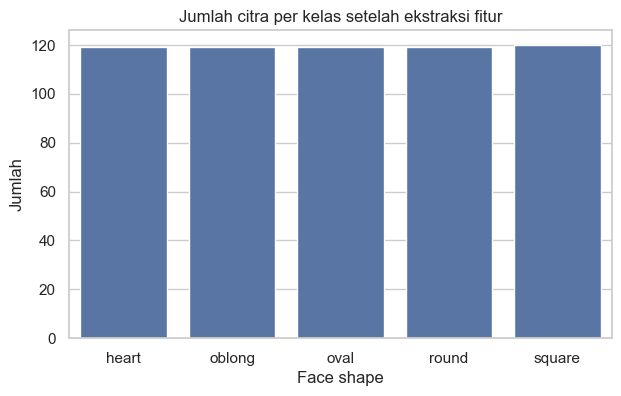

Jumlah fitur: 20
['D1_norm', 'D2_norm', 'D3_norm', 'D4_norm', 'D5_norm', 'D6_norm', 'D7_norm', 'R1', 'R2', 'R3', 'R4', 'R5', 'R6', 'R7', 'R8', 'R9', 'R10', 'A1', 'A2', 'A3']


,count,mean,std,min,25%,50%,75%,max
D1_norm,596.0,0.186875,0.003916,0.173335,0.184428,0.186868,0.189277,0.202114
D2_norm,596.0,0.170002,0.005479,0.150504,0.166852,0.170479,0.173699,0.190220
D3_norm,596.0,0.248917,0.009731,0.224594,0.242496,0.248509,0.254631,0.280237
D4_norm,596.0,0.097583,0.004861,0.081920,0.094458,0.097683,0.100816,0.114923
D5_norm,596.0,0.158851,0.004156,0.146422,0.156180,0.158943,0.161469,0.173534
D6_norm,596.0,0.090479,0.002866,0.081538,0.088729,0.090257,0.092120,0.101682
D7_norm,596.0,0.047294,0.001612,0.041905,0.046293,0.047254,0.048217,0.052846
R1,596.0,0.910001,0.032052,0.787516,0.892024,0.911581,0.930535,1.021155
R2,596.0,0.752217,0.039843,0.642889,0.729047,0.753239,0.778230,0.866923
R3,596.0,0.684435,0.042038,0.555754,0.657783,0.689066,0.709359,0.807909


In [23]:
plt.figure(figsize=(7, 4))
sns.countplot(data=feat_df, x="label", order=CLASSES)
plt.title("Jumlah citra per kelas setelah ekstraksi fitur")
plt.xlabel("Face shape")
plt.ylabel("Jumlah")
plt.show()

FEATURE_COLS = [c for c in feat_df.columns if c not in ("label", "path")]
print("Jumlah fitur:", len(FEATURE_COLS))
print(FEATURE_COLS)

feat_df[FEATURE_COLS].describe().T


## 8. Seleksi fitur

Paper memakai PCA + rata-rata feature importance dari tiga classifier terbaik.
Di sini kita:
1. Latih Random Forest, Gradient Boosting, dan XGBoost (jika tersedia).
2. Ambil `feature_importances_`, rata-ratakan, lalu pilih `TOP_K_FEATURES`.
3. Tampilkan juga explained variance PCA sebagai pembanding.


In [24]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, HistGradientBoostingClassifier
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA

X_all = feat_df[FEATURE_COLS].replace([np.inf, -np.inf], np.nan).fillna(0)

# XGBoost mewajibkan label numerik 0..n-1, bukan string.
le = LabelEncoder()
y_all = le.fit_transform(feat_df["label"])
print("Mapping kelas:", dict(zip(le.classes_, range(len(le.classes_)))))

importance_models = {
    "RandomForest": RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    "GradientBoosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
}

try:
    from xgboost import XGBClassifier
    importance_models["XGBoost"] = XGBClassifier(
        n_estimators=300, max_depth=4, learning_rate=0.05,
        subsample=0.9, colsample_bytree=0.9,
        eval_metric="mlogloss", random_state=RANDOM_STATE, n_jobs=-1
    )
except Exception as e:
    print("XGBoost tidak tersedia, dilewati:", e)

importances = []
for name, model in importance_models.items():
    model.fit(X_all, y_all)
    if hasattr(model, "feature_importances_"):
        imp = pd.Series(model.feature_importances_, index=FEATURE_COLS, name=name)
        importances.append(imp)

imp_df = pd.concat(importances, axis=1)
imp_df["mean"] = imp_df.mean(axis=1)
imp_df = imp_df.sort_values("mean", ascending=False)
imp_df.head(20)


Mapping kelas: {'heart': 0, 'oblong': 1, 'oval': 2, 'round': 3, 'square': 4}


,RandomForest,GradientBoosting,XGBoost,mean
R2,0.078798,0.149685,0.132059,0.120181
D5_norm,0.077691,0.064859,0.068570,0.070373
R4,0.049392,0.083163,0.059837,0.064131
A2,0.057612,0.077588,0.048260,0.061153
D3_norm,0.070812,0.050148,0.056678,0.059213
R3,0.057404,0.058756,0.053287,0.056483
A1,0.050081,0.048250,0.046276,0.048202
R6,0.045285,0.054749,0.044472,0.048168
D1_norm,0.053569,0.033039,0.052794,0.046468
R9,0.047713,0.043649,0.046861,0.046074


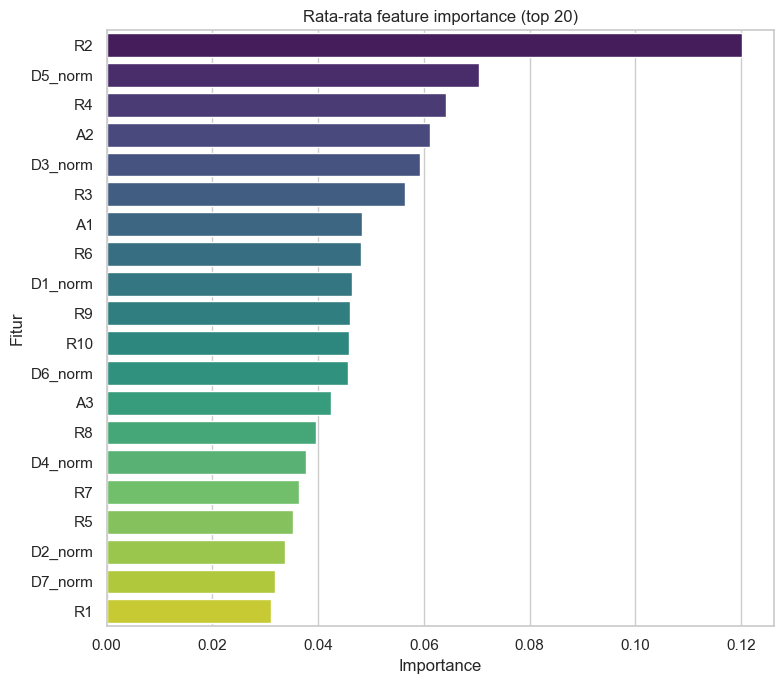

Fitur terpilih: ['R2', 'D5_norm', 'R4', 'A2', 'D3_norm', 'R3', 'A1', 'R6', 'D1_norm', 'R9', 'R10', 'D6_norm', 'A3', 'R8']


In [25]:
plt.figure(figsize=(8, 7))
sns.barplot(x=imp_df["mean"].head(20).values, y=imp_df.head(20).index, palette="viridis")
plt.title("Rata-rata feature importance (top 20)")
plt.xlabel("Importance")
plt.ylabel("Fitur")
plt.tight_layout()
plt.show()

SELECTED_FEATURES = imp_df.head(TOP_K_FEATURES).index.tolist()
print("Fitur terpilih:", SELECTED_FEATURES)


In [26]:
# PCA sebagai pembanding (paper memakai PCA)
X_scaled = StandardScaler().fit_transform(X_all)
pca = PCA(n_components=0.95, random_state=RANDOM_STATE).fit(X_scaled)
print("Jumlah komponen PCA (95% variance):", pca.n_components_)
print("Explained variance total:", round(pca.explained_variance_ratio_.sum(), 4))


Jumlah komponen PCA (95% variance): 6
Explained variance total: 0.9751


## 9. Training dan evaluasi model

Semua model memakai **5-fold stratified cross-validation** dan pipeline `StandardScaler + classifier`.


In [27]:
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

X = feat_df[SELECTED_FEATURES].replace([np.inf, -np.inf], np.nan).fillna(0)
y = le.transform(feat_df["label"])   # label numerik untuk semua classifier

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

models = {
    "RandomForest": RandomForestClassifier(n_estimators=400, random_state=RANDOM_STATE, n_jobs=-1),
    "GradientBoosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
    "SVM (RBF)": SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE),
    "KNN (k=5)": KNeighborsClassifier(n_neighbors=5),
    "LogisticRegression": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
}

try:
    from xgboost import XGBClassifier
    models["XGBoost"] = XGBClassifier(
        n_estimators=400, max_depth=4, learning_rate=0.05,
        subsample=0.9, colsample_bytree=0.9,
        eval_metric="mlogloss", random_state=RANDOM_STATE, n_jobs=-1
    )
except Exception:
    pass

results = []
for name, clf in models.items():
    pipe = make_pipeline(StandardScaler(), clf)
    scores = cross_val_score(pipe, X, y, cv=cv, scoring="accuracy", n_jobs=-1)
    results.append({"model": name, "mean_acc": scores.mean(), "std": scores.std()})
    print(f"{name:20s} accuracy = {scores.mean():.4f} +/- {scores.std():.4f}")

results_df = pd.DataFrame(results).sort_values("mean_acc", ascending=False)
results_df


RandomForest         accuracy = 0.5185 +/- 0.0478
GradientBoosting     accuracy = 0.4866 +/- 0.0562
SVM (RBF)            accuracy = 0.5319 +/- 0.0688
KNN (k=5)            accuracy = 0.4648 +/- 0.0162
LogisticRegression   accuracy = 0.5336 +/- 0.0694
XGBoost              accuracy = 0.5134 +/- 0.0582


,model,mean_acc,std
4,LogisticRegression,0.533557,0.069398
2,SVM (RBF),0.531905,0.068770
0,RandomForest,0.518473,0.047806
5,XGBoost,0.513389,0.058225
1,GradientBoosting,0.486639,0.056216
3,KNN (k=5),0.464790,0.016217


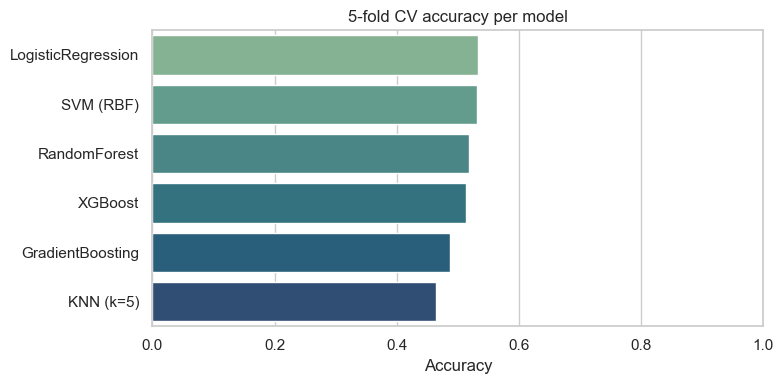

Model terbaik: LogisticRegression


In [28]:
plt.figure(figsize=(8, 4))
sns.barplot(data=results_df, x="mean_acc", y="model", palette="crest")
plt.xlim(0, 1)
plt.title("5-fold CV accuracy per model")
plt.xlabel("Accuracy")
plt.ylabel("")
plt.tight_layout()
plt.show()

best_name = results_df.iloc[0]["model"]
best_clf = models[best_name]
best_pipe = make_pipeline(StandardScaler(), best_clf)
print("Model terbaik:", best_name)


## 10. Confusion matrix model terbaik

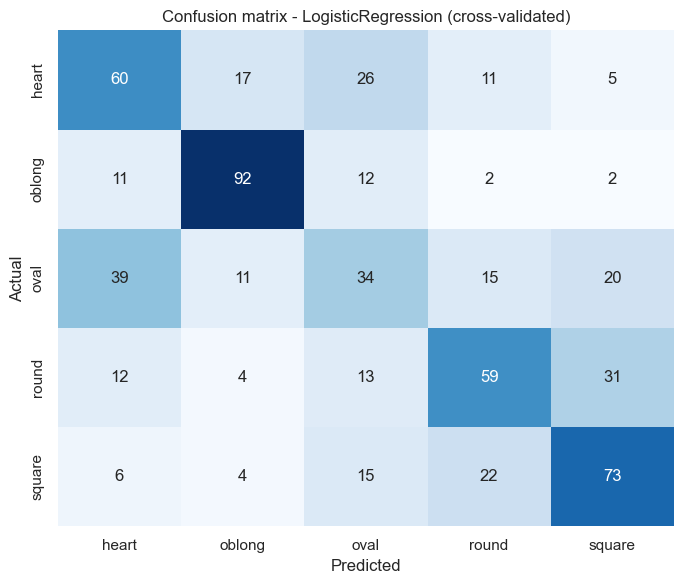

              precision    recall  f1-score   support

       heart     0.4688    0.5042    0.4858       119
      oblong     0.7188    0.7731    0.7449       119
        oval     0.3400    0.2857    0.3105       119
       round     0.5413    0.4958    0.5175       119
      square     0.5573    0.6083    0.5817       120

    accuracy                         0.5336       596
   macro avg     0.5252    0.5334    0.5281       596
weighted avg     0.5253    0.5336    0.5282       596



In [29]:
y_pred = cross_val_predict(best_pipe, X, y, cv=cv, n_jobs=-1)
labels_present = list(range(len(le.classes_)))

cm = confusion_matrix(y, y_pred, labels=labels_present)
cm_df = pd.DataFrame(cm, index=le.classes_, columns=le.classes_)

plt.figure(figsize=(7, 6))
sns.heatmap(cm_df, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title(f"Confusion matrix - {best_name} (cross-validated)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

print(classification_report(y, y_pred, target_names=le.classes_, digits=4))


## 11. Latih model final pada seluruh data dan simpan

In [30]:
import joblib

final_model = make_pipeline(StandardScaler(), best_clf)
final_model.fit(X, y)

joblib.dump(final_model, OUTPUT_DIR / "face_shape_model.joblib")
joblib.dump(SELECTED_FEATURES, OUTPUT_DIR / "selected_features.joblib")
joblib.dump(le, OUTPUT_DIR / "label_encoder.joblib")
feat_df.to_csv(OUTPUT_DIR / "face_shape_features.csv", index=False)

print("Disimpan ke:", OUTPUT_DIR.resolve())
print(sorted(os.listdir(OUTPUT_DIR)))


Disimpan ke: D:\Kuliah\Semester5\PCVK\Tugas Akhir\output
['face_shape_features.csv', 'face_shape_model.joblib', 'label_encoder.joblib', 'selected_features.joblib']


## 12. Prediksi gambar baru

Ganti `IMAGE_PATH` dengan path gambar wajah frontal.


In [31]:
def predict_face_shape(image_path, model, feature_names, label_encoder):
    img = cv2.imread(str(image_path))
    if img is None:
        raise FileNotFoundError(image_path)
    pts = get_landmarks(img)
    feats = features_from_landmarks(pts)
    if feats is None:
        raise RuntimeError("Wajah/landmark tidak terdeteksi.")
    x = pd.DataFrame([feats])[feature_names].replace([np.inf, -np.inf], np.nan).fillna(0)
    pred_idx = int(model.predict(x)[0])
    pred = label_encoder.inverse_transform([pred_idx])[0]
    proba = float(model.predict_proba(x).max()) if hasattr(model, "predict_proba") else None
    return pred, proba, pts

IMAGE_PATH = ""  # contoh: "contoh_wajah.jpg"

if IMAGE_PATH and Path(IMAGE_PATH).exists():
    pred, proba, pts = predict_face_shape(IMAGE_PATH, final_model, SELECTED_FEATURES, le)
    print(f"Prediksi: {pred}" + (f" | confidence: {proba:.3f}" if proba else ""))

    img = cv2.imread(IMAGE_PATH)
    vis = img.copy()
    if pts is not None:
        for i in [2, 14, 69, 75, 79, 72, 8, 12, 4, 6, 10, 7, 9]:
            cv2.circle(vis, tuple(pts[i].astype(int)), 2, (0, 255, 0), -1)
    plt.figure(figsize=(5, 5))
    plt.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
    plt.axis("off")
    plt.title(f"Prediksi: {pred}")
    plt.show()
else:
    print("Set IMAGE_PATH untuk mencoba prediksi.")


Set IMAGE_PATH untuk mencoba prediksi.


## 13. Tes menggunakan kamera laptop

Sel ini membuka kamera, mendeteksi wajah secara real-time, menghitung fitur, lalu menampilkan prediksi bentuk wajah beserta confidence.

**Kontrol:**
- **Q** atau **Esc** → keluar
- **S** → simpan frame ke folder `output/`

**Catatan Windows:** kamera dibuka dengan backend `CAP_DSHOW` agar lebih stabil. Jika kamera tidak terbuka, coba ganti `camera_index` (0, 1, 2, ...).


In [34]:
import time
from collections import deque, Counter

def run_webcam(model, feature_names, label_encoder, camera_index=0, smooth=7):
    cap = cv2.VideoCapture(camera_index, cv2.CAP_DSHOW)
    if not cap.isOpened():
        cap = cv2.VideoCapture(camera_index)
    if not cap.isOpened():
        raise RuntimeError(
            "Kamera tidak bisa dibuka. Cek camera_index, tutup aplikasi lain yang memakai kamera, "
            "atau izin kamera Windows."
        )

    history = deque(maxlen=smooth)
    print("Kamera aktif. Tekan Q untuk keluar, S untuk menyimpan frame.")
    try:
        while True:
            ok, frame = cap.read()
            if not ok:
                print("Frame tidak terbaca.")
                break

            frame = cv2.flip(frame, 1)  # mirror
            pts = get_landmarks(frame)
            text, color = "Wajah tidak terdeteksi", (0, 0, 255)

            if pts is not None:
                feats = features_from_landmarks(pts)
                if feats is not None:
                    x = (pd.DataFrame([feats])[feature_names]
                         .replace([np.inf, -np.inf], np.nan).fillna(0))
                    proba = model.predict_proba(x)[0]
                    idx = int(np.argmax(proba))
                    conf = float(proba[idx])

                    # smoothing: mayoritas prediksi beberapa frame terakhir
                    history.append(idx)
                    idx_smooth = Counter(history).most_common(1)[0][0]
                    label = label_encoder.inverse_transform([idx_smooth])[0]
                    text = f"{label}  ({conf:.2f})"
                    color = (0, 255, 0)

                    for i in [2, 14, 69, 75, 79, 72, 8, 12, 4, 6, 10, 7, 9]:
                        cv2.circle(frame, tuple(pts[i].astype(int)), 2, (0, 255, 0), -1)

            # panel teks
            cv2.rectangle(frame, (0, 0), (frame.shape[1], 80), (0, 0, 0), -1)
            cv2.putText(frame, text, (15, 35), cv2.FONT_HERSHEY_SIMPLEX, 0.9, color, 2)
            cv2.putText(frame, "Q: keluar | S: simpan", (15, 65),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.55, (255, 255, 255), 1)

            cv2.imshow("Face Shape - Webcam", frame)
            key = cv2.waitKey(1) & 0xFF
            if key in (ord("q"), 27):
                break
            if key == ord("s"):
                out = OUTPUT_DIR / f"webcam_{int(time.time())}.jpg"
                cv2.imwrite(str(out), frame)
                print("Disimpan:", out)
    finally:
        cap.release()
        cv2.destroyAllWindows()
        cv2.waitKey(1)

# Jalankan:
run_webcam(final_model, SELECTED_FEATURES, le, camera_index=0)


Kamera aktif. Tekan Q untuk keluar, S untuk menyimpan frame.


### Alternatif: ambil satu frame lalu prediksi (tanpa jendela real-time)

Berguna kalau `cv2.imshow` bermasalah di Jupyter.


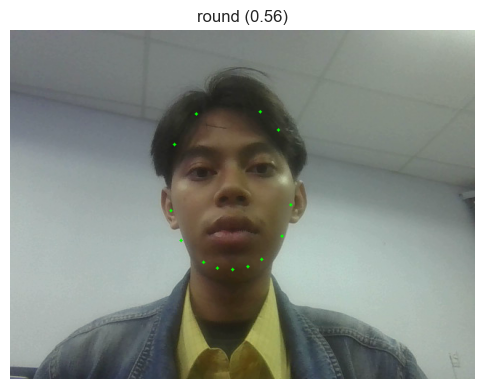

('round', 0.5555856323392545)

In [40]:
def capture_and_predict(model, feature_names, label_encoder, camera_index=0):
    cap = cv2.VideoCapture(camera_index, cv2.CAP_DSHOW)
    if not cap.isOpened():
        cap = cv2.VideoCapture(camera_index)
    ok, frame = cap.read()
    cap.release()
    if not ok:
        raise RuntimeError("Gagal membaca frame kamera.")

    frame = cv2.flip(frame, 1)
    pts = get_landmarks(frame)
    feats = features_from_landmarks(pts)
    if feats is None:
        raise RuntimeError("Wajah tidak terdeteksi.")

    x = pd.DataFrame([feats])[feature_names].replace([np.inf, -np.inf], np.nan).fillna(0)
    idx = int(model.predict(x)[0])
    label = label_encoder.inverse_transform([idx])[0]
    conf = float(model.predict_proba(x).max())

    vis = frame.copy()
    for i in [2, 14, 69, 75, 79, 72, 8, 12, 4, 6, 10, 7, 9]:
        cv2.circle(vis, tuple(pts[i].astype(int)), 2, (0, 255, 0), -1)

    plt.figure(figsize=(6, 5))
    plt.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
    plt.axis("off")
    plt.title(f"{label} ({conf:.2f})")
    plt.show()
    return label, conf

capture_and_predict(final_model, SELECTED_FEATURES, le)


## 14. Catatan dan keterbatasan

1. **Perbedaan dengan paper**
   - Paper memakai 124 citra bersih dari 5.000 citra; notebook ini memakai subset acak (`MAX_PER_CLASS`) atau seluruh dataset.
   - Paper melaporkan **70%** dengan Gradient Boosted Trees; hasil di sini bisa berbeda karena pembersihan data dan pemilihan fitur tidak identik.

2. **Kualitas landmark**
   - Dlib 81-point tetap bisa salah pada wajah miring, tertutup rambut, atau resolusi rendah.
   - Citra non-frontal sebaiknya dibuang.

3. **Normalisasi**
   - Jarak dinormalisasi dengan jumlah 7 jarak, sehingga bebas dari skala resolusi.
   - Rasio dan sudut membantu membedakan oval vs oblong vs heart.

4. **Pengembangan**
   - Tambahkan MediaPipe FaceMesh sebagai backend alternatif.
   - Coba augmentasi, selector fitur (RFE), dan hyperparameter tuning.
   - Evaluasi per kelas dengan balanced accuracy / macro F1.

5. **Dataset**
   - Kaggle Face Shape Dataset: 5.000 citra, 5 kelas, lisensi mengikuti Kaggle.
   - Beberapa label di dataset asli dilaporkan tidak akurat; pembersihan manual tetap diperlukan.

---
**Referensi**
- Mehta, A., & Mahmoud, T. M. *Human Face Shape Classification with Machine Learning*.
- Dlib 81-point model: https://github.com/codeniko/shape_predictor_81_face_landmarks
- Kaggle Face Shape Dataset: https://www.kaggle.com/datasets/niten19/face-shape-dataset


## 15. Troubleshooting

| Masalah | Solusi |
|---|---|
| `pip install dlib` gagal di Windows | **Pakai `pip install dlib-bin`** (wheel prebuilt, tersedia untuk Python 3.10–3.15). Alternatif: `conda install -c conda-forge dlib` atau Python 3.11 |
| `kagglehub` gagal / 403 | Set `KAGGLE_USERNAME` dan `KAGGLE_KEY`, atau unduh ZIP dataset manual lalu set `DATA_DIR` |
| Wajah tidak terdeteksi | Gunakan foto frontal, pencahayaan cukup, wajah tidak tertutup; coba `detector(gray, 0)` |
| Hasil akurasi jauh dari 70% | Dataset asli berisik; kurangi `MAX_PER_CLASS`, buang citra non-frontal, atau gunakan subset 124 citra bersih seperti paper |
| Proses ekstraksi lambat | Turunkan `MAX_PER_CLASS`, jalankan di GPU tidak membantu karena dlib CPU-bound |
| `XGBoost` tidak terpasang | Notebook otomatis melewati XGBoost; model lain tetap berjalan |
| `Invalid classes inferred from unique values of y` | Label sudah di-encode dengan `LabelEncoder`; jalankan ulang dari sel seleksi fitur |
| Kamera tidak terbuka | Ganti `camera_index` (0/1/2), tutup Zoom/Teams, cek izin kamera Windows |
| Jendela kamera freeze di Jupyter | Tekan Q, lalu restart kernel; gunakan sel `capture_and_predict` sebagai alternatif |
| Prediksi kamera berubah-ubah | Naikkan `smooth` (mis. 10–15) atau pastikan pencahayaan cukup |

---
## 16. Ringkasan

Notebook ini mereproduksi alur paper:
**gambar → Dlib 81 landmark → 20 fitur geometris → seleksi fitur → classifier → evaluasi**.

Hasil yang diharapkan:
- Baseline akurasi sekitar **60–75%** pada subset kecil, tergantung kualitas landmark dan pembersihan data.
- Kelas **round** dan **square** biasanya lebih mudah dipisahkan; **oval vs oblong vs heart** lebih sulit.
